In [1]:
# Pandas para manipular o dataset como tabela (DataFrame).

import pandas as pd

In [2]:
# Carrega o dataset rotulado e descarta linhas sem categoria.
# shape = (linhas, colunas) do dataset final usado no treino.

df = pd.read_csv("../data/processed/rotulado_v1.csv")
df = df.dropna(subset=["categoria"])  
df.shape

(667, 4)

In [3]:
# Distribuição das classes: mostra o desbalanceamento do dataset.

df["categoria"].value_counts()

categoria
Alimentação      163
Outros           122
Compras          104
Lazer             59
Transferência     55
Mercado           53
Transporte        53
Saúde             32
Assinaturas       13
Moradia            8
Educação           5
Name: count, dtype: int64

In [4]:
# Features (X) e rótulo (y), na convenção do scikit-learn:
# X = texto bruto da transação (entrada), y = categoria (o que queremos prever).

X = df["descricao"]
y = df["categoria"]

In [5]:
# Divisão treino/teste (80/20).

from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.2,      # 20% p/ teste
    stratify=y,         
    random_state=42,   
)
len(X_treino), len(X_teste)

(533, 134)

In [6]:
# TF-IDF: transforma cada descrição num vetor numérico, uma coluna por palavra do vocabulário.
# Palavras comuns a tudo ("Compra", "Bra") recebem peso baixo; palavras raras e informativas, peso alto.
# fit só no treino (aprende o vocabulário); no teste apenas transform, para não vazar informação.

from sklearn.feature_extraction.text import TfidfVectorizer

vetorizador = TfidfVectorizer(lowercase=True)

X_treino_num = vetorizador.fit_transform(X_treino)   
X_teste_num  = vetorizador.transform(X_teste)       
X_treino_num.shape

(533, 859)

In [7]:
# Amostra do vocabulário aprendido pelo TF-IDF.

vetorizador.get_feature_names_out()[:50]

array(['0001', '00021', '0033', '0077', '00a2dacb', '01', '0196', '0197',
       '02', '0237', '0260', '03', '0301', '0341', '0383', '04', '0401',
       '05', '06', '0665', '0675', '0694', '074f', '08', '08834', '08836',
       '09', '10', '106', '11', '114', '118', '12', '1228fe80', '1250',
       '1712', '189', '194', '194sao', '197', '1a99', '1t', '2026', '236',
       '2462', '3724', '372574', '3730', '3734', '394'], dtype=object)

In [8]:
# Regressão Logística multiclasse: aprende um peso por palavra para cada categoria
# e escolhe a categoria com maior pontuação. max_iter=1000 garante a convergência.

from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_treino_num, y_treino)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [9]:
# Acurácia

from sklearn.metrics import accuracy_score

previsoes = modelo.predict(X_teste_num)
accuracy_score(y_teste, previsoes)

0.6044776119402985

In [10]:
# Baseline trivial (piso): acurácia de um modelo que sempre chuta a classe mais frequente.

y_teste.value_counts(normalize=True).max()

np.float64(0.2462686567164179)

In [11]:
# Teste com descrições inventadas, para ver o comportamento do modelo
# em lojas que podem não existir no treino.

testes = [
    "Compra no débito - Uber *uber *trip Sao Paulo Bra",
    "IFD*PIZZARIA DO ZE",
    "Pix enviado - PESSOA - NU PAGAMENTOS - IP",
    "Compra no débito - Drogasil Santo Andre Bra",
    "NETFLIX.COM",
]
modelo.predict(vetorizador.transform(testes))

array(['Alimentação', 'Alimentação', 'Transferência', 'Alimentação',
       'Outros'], dtype=object)

In [12]:
# Probabilidade prevista para cada categoria (predict_proba): mostra o grau de confiança do modelo.

probs = modelo.predict_proba(vetorizador.transform(testes))
pd.DataFrame(probs, columns=modelo.classes_, index=testes).round(2)

,Alimentação,Assinaturas,Compras,Educação,Lazer,Mercado,Moradia,Outros,Saúde,Transferência,Transporte
Compra no débito - Uber *uber *trip Sao Paulo Bra,0.26,0.02,0.12,0.01,0.07,0.07,0.01,0.16,0.05,0.03,0.20
IFD*PIZZARIA DO ZE,0.45,0.03,0.13,0.01,0.07,0.06,0.02,0.10,0.04,0.05,0.05
Pix enviado - PESSOA - NU PAGAMENTOS - IP,0.09,0.02,0.10,0.01,0.06,0.06,0.01,0.18,0.03,0.39,0.05
Compra no débito - Drogasil Santo Andre Bra,0.36,0.02,0.10,0.01,0.06,0.07,0.01,0.22,0.04,0.03,0.09
NETFLIX.COM,0.14,0.07,0.17,0.01,0.11,0.10,0.02,0.23,0.05,0.05,0.07


In [13]:
# Experimento: TF-IDF com n-gramas de caracteres (pedaços de 2 a 4 letras) em vez de palavras inteiras.
# Ajuda com nomes truncados ou colados pelos bancos (ex.: "Drogasil2705" ainda compartilha "drog", "gasi"...).

vetorizador_char = TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 4))

Xtr = vetorizador_char.fit_transform(X_treino)
Xte = vetorizador_char.transform(X_teste)

modelo_char = LogisticRegression(max_iter=1000).fit(Xtr, y_treino)
accuracy_score(y_teste, modelo_char.predict(Xte))

0.6567164179104478

In [14]:
# Análise de erros: lista as descrições do teste em que a previsão difere do rótulo real.

erros = pd.DataFrame({
    "descricao": X_teste,
    "real": y_teste,
    "previsto": previsoes,
})

erros[erros["real"] != erros["previsto"]]


,descricao,real,previsto
385,ZIG*ARENA 40 GRAUS,Alimentação,Lazer
430,SAMSONITE BRASIL LTDA,Compras,Lazer
429,Goldenmeias,Compras,Alimentação
521,MANIA DE CHURRASCO,Alimentação,Outros
115,SEGURO SUPERPROTEGIDO,Outros,Alimentação
27,Compra no débito - Hs Metropole Sbc Sao Bernar...,Transporte,Alimentação
508,PONTO MGM,Outros,Alimentação
112,StereoCar 01/08,Transporte,Compras
79,Compra no débito - SOCIEDADE RELIGIOSA R,Outros,Alimentação
552,TRICOLAR,Outros,Alimentação


In [15]:
# Acerto por categoria das piores para as melhores.
# count = exemplos da categoria no teste; com poucos exemplos, a taxa é pouco confiável.

tabela = pd.DataFrame({
    "descricao": X_teste,
    "real": y_teste,
    "previsto": previsoes,
})
tabela["acertou"] = tabela["real"] == tabela["previsto"]

por_categoria = tabela.groupby("real")["acertou"].agg(["mean", "count"])
por_categoria.sort_values("mean")

,mean,count
real,,
Assinaturas,0.000000,3
Educação,0.000000,1
Moradia,0.000000,1
Mercado,0.272727,11
Transporte,0.272727,11
Saúde,0.333333,6
Compras,0.523810,21
Outros,0.541667,24
Lazer,0.583333,12


In [16]:
# Pipeline: encadeia TF-IDF + Regressão Logística num único objeto.
# Garante que o vetorizador seja ajustado só com dados de treino.

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


modelo = make_pipeline(
    TfidfVectorizer(lowercase=True),
    LogisticRegression(max_iter=1000),
)
modelo.fit(X_treino, y_treino)          
previsoes = modelo.predict(X_teste)     

In [17]:
# Relatório por categoria:
# precision = das vezes que previu a classe, quantas estavam certas;
# recall = dos exemplos reais da classe, quantos foram encontrados;
# f1-score = média harmônica entre as duas; support = exemplos no teste.

from sklearn.metrics import classification_report

print(classification_report(y_teste, previsoes, zero_division=0))

               precision    recall  f1-score   support

  Alimentação       0.44      0.94      0.60        33
  Assinaturas       0.00      0.00      0.00         3
      Compras       0.69      0.52      0.59        21
     Educação       0.00      0.00      0.00         1
        Lazer       0.78      0.58      0.67        12
      Mercado       1.00      0.27      0.43        11
      Moradia       0.00      0.00      0.00         1
       Outros       0.68      0.54      0.60        24
        Saúde       1.00      0.33      0.50         6
Transferência       1.00      1.00      1.00        11
   Transporte       1.00      0.27      0.43        11

     accuracy                           0.60       134
    macro avg       0.60      0.41      0.44       134
 weighted avg       0.70      0.60      0.58       134



In [18]:
# F1 macro: média do F1 de cada categoria, todas com o mesmo peso.
# Mostra se o modelo vai bem em TODAS as categorias, não só nas com mais dados.
# Métrica principal do projeto, por causa do desbalanceamento.

from sklearn.metrics import f1_score

f1_score(y_teste, previsoes, average="macro")

0.43863609352433014

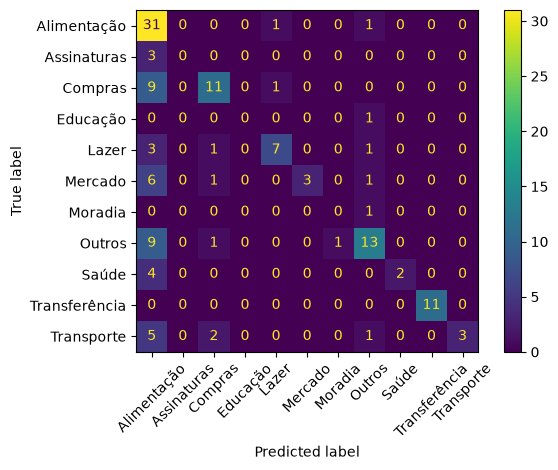

In [19]:
# Matriz de confusão: linhas = categoria real, colunas = categoria prevista.
# A diagonal são os acertos; fora dela, quais categorias o modelo confunde entre si.

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_teste, previsoes, xticks_rotation=45)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

notas = cross_val_score(modelo, X, y, cv=cv, scoring="f1_macro")
print(notas.round(3))
print(f"F1 macro: {notas.mean():.3f} ± {notas.std():.3f}")

[0.415 0.481 0.4   0.42  0.391]
F1 macro: 0.421 ± 0.032


In [ ]:
modelo_letras = make_pipeline(
    TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 4)),
    LogisticRegression(max_iter=1000),
)
notas_letras = cross_val_score(modelo_letras, X, y, cv=cv, scoring="accuracy")
print(f"Acurácia (letras): {notas_letras.mean():.3f} ± {notas_letras.std():.3f}")

Acurácia (letras): 0.471 ± 0.031


In [30]:
modelo_balanceado = make_pipeline(
    TfidfVectorizer(lowercase=True),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
notas_bal = cross_val_score(modelo_balanceado, X, y, cv=cv, scoring="accuracy")
print(f"Acurácia (balanceado): {notas_bal.mean():.3f} ± {notas_bal.std():.3f}")

Acurácia (balanceado): 0.610 ± 0.033


In [29]:
modelo_combo = make_pipeline(
    TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 4)),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

notas_combo = cross_val_score(modelo_combo, X, y, cv=cv, scoring="accuracy")
print(f"Acurácia (letras + balanceado): {notas_combo.mean():.3f} ± {notas_combo.std():.3f}")

Acurácia (letras + balanceado): 0.663 ± 0.033


In [23]:
modelo_combo = make_pipeline(
    TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 4)),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

notas_combo = cross_val_score(modelo_combo, X, y, cv=cv, scoring="f1_macro")
print(f"f1-macro: (letras + balanceado): {notas_combo.mean():.3f} ± {notas_combo.std():.3f}")

f1-macro: (letras + balanceado): 0.614 ± 0.068


In [25]:
tabela = pd.DataFrame({"descricao": X_teste, "real": y_teste, "previsto": previsoes})
tabela = tabela.join(df[["fonte", "banco"]])     
tabela["acertou"] = tabela["real"] == tabela["previsto"]

tabela.groupby("banco")["acertou"].agg(["mean", "count"])


,mean,count
banco,,
Bradesco,0.000000,8
Inter,0.681818,44
Itaú,0.594203,69
Nubank,0.769231,13
